# Система прогнозирования продаж для «Прилавка»

## Описание задачи

Наш клиент — компания «Прилавок», новая сеть дарксторов в России, специализирующаяся на быстрой доставке продуктов и товаров повседневного спроса. Компания работает с 2023 года и управляет более чем 45 дарксторами.

**Бизнес-проблема**

Эффективность дарксторов критически зависит от точности управления запасами. Текущая система планирования закупок работает на субъективных оценках аналитиков, что приводит к разным проблемам:
- К дефициту товаров в пиковые периоды (недополучение 3–5% выручки).
- К избыточным запасам и списаниям продуктов с коротким сроком годности (2–3% от выручки).
- К неэффективному использованию времени аналитиков (15–20 часов в неделю на ручное планирование).

**Цель проекта**

Разработать автоматизированную систему прогнозирования недельных продаж для каждого отдела во всех дарксторах с использованием машинного обучения (модель CatBoost). Система будет работать в режиме пакетного внедрения с недельным циклом: модель будет переобучаться каждое воскресенье вечером, а к понедельнику утром прогнозы будут готовы для передачи в систему планирования закупок.

## Описание данных

Для работы доступны исторические данные о продажах за февраль 2023 — октябрь 2025, организованные в виде нескольких таблиц в PostgreSQL:

1. Таблица `sales` — исторические данные о продажах:
   - `Store` — номер даркстора (1–45).
   - `Dept` — номер отдела внутри даркстора (1–99).
   - `Date` — неделя (дата начала недели).
   - `Weekly_Sales` — недельные продажи (руб., целевая переменная).
   - `IsHoliday` — признак праздничной недели.

2. Таблица `stores` — информация о дарксторах:
   - `Store` — номер даркстора.
   - `Type` — тип даркстора (A, B, C).
   - `Size` — размер даркстора в условных единицах.

3. Таблица `features` — внешние факторы:
   - `Store`, `Date` — идентификаторы.
   - `Temperature` — средняя температура за неделю.
   - `Fuel_Price` — средняя цена бензина.
   - `MarkDown1-5` — факторы рекламных акций и скидок.
   - `CPI` — индекс потребительских цен.
   - `Unemployment` — уровень безработицы.

4. Таблица `plan` — данные для инференса (ноябрь 2025 — июль 2026), содержит те же столбцы, что и `sales`, кроме `Weekly_Sales`.

## План работы

1. Первичный анализ и очистка данных.
2. Предобработка и создание признаков.
3. Мониторинг стабильности признаков (PSI).
4. Обучение модели CatBoost и оценка качества.



In [1]:
!pip install phik -q

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine, text
import psycopg2
from phik import phik_matrix
import warnings
warnings.filterwarnings("ignore")

Фиксируем `random_state` для воспроизводимости результатов.

In [3]:
RANDOM_STATE = 42

### Шаг 1. Первичный анализ данных

In [4]:
# --- Подключение ---
host = "rc1d-pdq3kahro9enkfir.mdb.yandexcloud.net"
port = 6432
database = "playground_ds_20260915_7e2a105f57"
user = "    "
password = "    "

conn_str = f"postgresql+psycopg2://{user}:{password}@{host}:{port}/{database}"
engine = create_engine(conn_str)

with engine.connect() as conn:
    print("✅ Соединение:", conn.execute(text("SELECT 1")).fetchone())

✅ Соединение: (1,)


In [5]:
# --- Выгрузка данных ---
print("📥 Загрузка таблиц из PostgreSQL...")
df_sales = pd.read_sql_query(text("SELECT * FROM sales"), engine)
df_stores = pd.read_sql_query(text("SELECT * FROM stores"), engine)
df_features = pd.read_sql_query(text("SELECT * FROM features"), engine)

print(f"✅ Продажи: {len(df_sales)} строк")
print(f"✅ Дарксторы: {len(df_stores)} строк")
print(f"✅ Внешние факторы: {len(df_features)} строк")

📥 Загрузка таблиц из PostgreSQL...
✅ Продажи: 421570 строк
✅ Дарксторы: 45 строк
✅ Внешние факторы: 421570 строк


In [6]:
display(df_sales.head())
display(df_stores.head())
display(df_features.head())

,store,dept,date,weekly_sales,is_holiday
0,1,1,2023-02-05,24924.50,False
1,29,5,2023-02-05,15552.08,False
2,29,6,2023-02-05,3200.22,False
3,29,7,2023-02-05,10820.05,False
4,29,8,2023-02-05,20055.64,False


,store,type,size
0,1,A,151315
1,2,A,202307
2,3,B,37392
3,4,A,205863
4,5,B,34875


,store,dept,date,temperature,fuel_price,factor1,factor2,factor3,factor4,factor5,cpi,unemployment
0,1,1,2023-02-05,42.31,2.572,7028.8,NaN,NaN,NaN,NaN,211.096358,8.106
1,29,5,2023-02-05,24.36,2.788,7028.8,NaN,NaN,NaN,NaN,131.527903,10.064
2,29,6,2023-02-05,24.36,2.788,7028.8,NaN,NaN,NaN,NaN,131.527903,10.064
3,29,7,2023-02-05,24.36,2.788,7028.8,NaN,NaN,NaN,NaN,131.527903,10.064
4,29,8,2023-02-05,24.36,2.788,7028.8,NaN,NaN,NaN,NaN,131.527903,10.064


In [7]:
display(df_sales.info())
display(df_stores.info())
display(df_features.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 421570 entries, 0 to 421569
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   store         421570 non-null  int64  
 1   dept          421570 non-null  int64  
 2   date          421570 non-null  object 
 3   weekly_sales  421570 non-null  float64
 4   is_holiday    421570 non-null  bool   
dtypes: bool(1), float64(1), int64(2), object(1)
memory usage: 13.3+ MB


None

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45 entries, 0 to 44
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   store   45 non-null     int64 
 1   type    45 non-null     object
 2   size    45 non-null     int64 
dtypes: int64(2), object(1)
memory usage: 1.2+ KB


None

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 421570 entries, 0 to 421569
Data columns (total 12 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   store         421570 non-null  int64  
 1   dept          421570 non-null  int64  
 2   date          421570 non-null  object 
 3   temperature   421570 non-null  float64
 4   fuel_price    421570 non-null  float64
 5   factor1       421570 non-null  float64
 6   factor2       111248 non-null  float64
 7   factor3       137091 non-null  float64
 8   factor4       134967 non-null  float64
 9   factor5       151432 non-null  float64
 10  cpi           421570 non-null  float64
 11  unemployment  421570 non-null  float64
dtypes: float64(9), int64(2), object(1)
memory usage: 38.6+ MB


None

In [8]:
def analyze_missing(df, name):
    total = len(df)
    missing_info = df.isna().sum()
    missing_pct = (missing_info / total * 100).round(2)
    report = pd.DataFrame({'Missing_Count': missing_info, 'Missing_Pct': missing_pct})
    report = report[report['Missing_Count'] > 0].sort_values('Missing_Count', ascending=False)
    print(f"\n--- {name}: пропуски ---")
    if report.empty:
        print("Пропусков нет.")
    else:
        print(report)
    return report

def clean_table(df, name, special_fill=None):
    """
    special_fill: dict {col: value} — для колонок с особой логикой (например, MarkDown -> 0)
    """
    original_len = len(df)
    
    # 1. Дубликаты
    duplicates_count = df.duplicated().sum()
    df = df.drop_duplicates()
    print(f"✅ {name}: удалено {duplicates_count} полных дубликатов строк.")

    # 2. Пропуски: сначала спец-логика
    if special_fill:
        for col, val in special_fill.items():
            if col in df.columns:
                before = df[col].isna().sum()
                df[col] = df[col].fillna(val)
                print(f"   → {col}: заполнено {before} пропусков значением {val}")

    # 3. Разделение на числовые и категориальные
    num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
    cat_cols = df.select_dtypes(exclude=[np.number]).columns.tolist()

    categorical_by_meaning = ['Store', 'Dept']
    for c in categorical_by_meaning:
        if c in num_cols:
            num_cols.remove(c)
            cat_cols.append(c)

    # Заполняем числовые — средним
    for col in num_cols:
        if df[col].isna().any():
            before = df[col].isna().sum()
            mean_val = df[col].mean()
            df[col] = df[col].fillna(mean_val)
            print(f"   → {col} (числовой): заполнено {before} пропусков средним = {mean_val:.2f}")

    # Заполняем категориальные — модой
    for col in cat_cols:
        if df[col].isna().any():
            before = df[col].isna().sum()
            mode_val = df[col].mode()[0] if not df[col].mode().empty else None
            if mode_val is not None:
                df[col] = df[col].fillna(mode_val)
                print(f"   → {col} (категориальный): заполнено {before} пропусков модой = {mode_val}")
            else:
                print(f"   → {col}: не удалось найти моду (все пропуски?)")

    print(f"✅ {name}: итоговая длина {len(df)} (было {original_len})")
    return df

# --- Обработка sales ---
print("🧹 Обработка таблицы sales")
df_sales_clean = clean_table(
    df_sales.copy(),
    "sales",
    special_fill={}  # здесь можно добавить спец-заполнения, если нужно
)
analyze_missing(df_sales_clean, "sales после очистки")

# --- Обработка stores ---
print("\n🧹 Обработка таблицы stores")
df_stores_clean = clean_table(
    df_stores.copy(),
    "stores",
    special_fill={}
)
analyze_missing(df_stores_clean, "stores после очистки")

# --- Обработка features ---
print("\n🧹 Обработка таблицы features")
# Для MarkDown логичнее 0 (нет акции), а не среднее
markdown_cols = [c for c in df_features.columns if c.startswith('MarkDown')]
special_fill_features = {c: 0 for c in markdown_cols}

df_features_clean = clean_table(
    df_features.copy(),
    "features",
    special_fill=special_fill_features
)
analyze_missing(df_features_clean, "features после очистки")

🧹 Обработка таблицы sales
✅ sales: удалено 0 полных дубликатов строк.
✅ sales: итоговая длина 421570 (было 421570)

--- sales после очистки: пропуски ---
Пропусков нет.

🧹 Обработка таблицы stores
✅ stores: удалено 0 полных дубликатов строк.
✅ stores: итоговая длина 45 (было 45)

--- stores после очистки: пропуски ---
Пропусков нет.

🧹 Обработка таблицы features
✅ features: удалено 0 полных дубликатов строк.
   → factor2 (числовой): заполнено 310322 пропусков средним = 3334.63
   → factor3 (числовой): заполнено 284479 пропусков средним = 1439.42
   → factor4 (числовой): заполнено 286603 пропусков средним = 3383.17
   → factor5 (числовой): заполнено 270138 пропусков средним = 4628.98
✅ features: итоговая длина 421570 (было 421570)

--- features после очистки: пропуски ---
Пропусков нет.


,Missing_Count,Missing_Pct


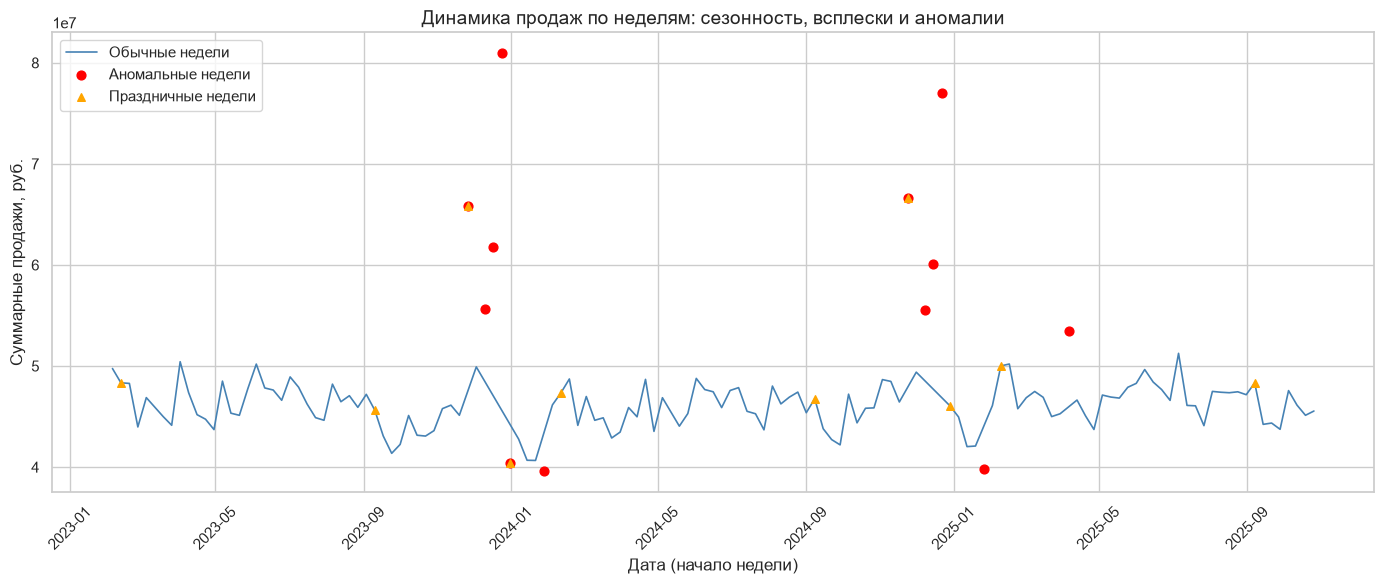

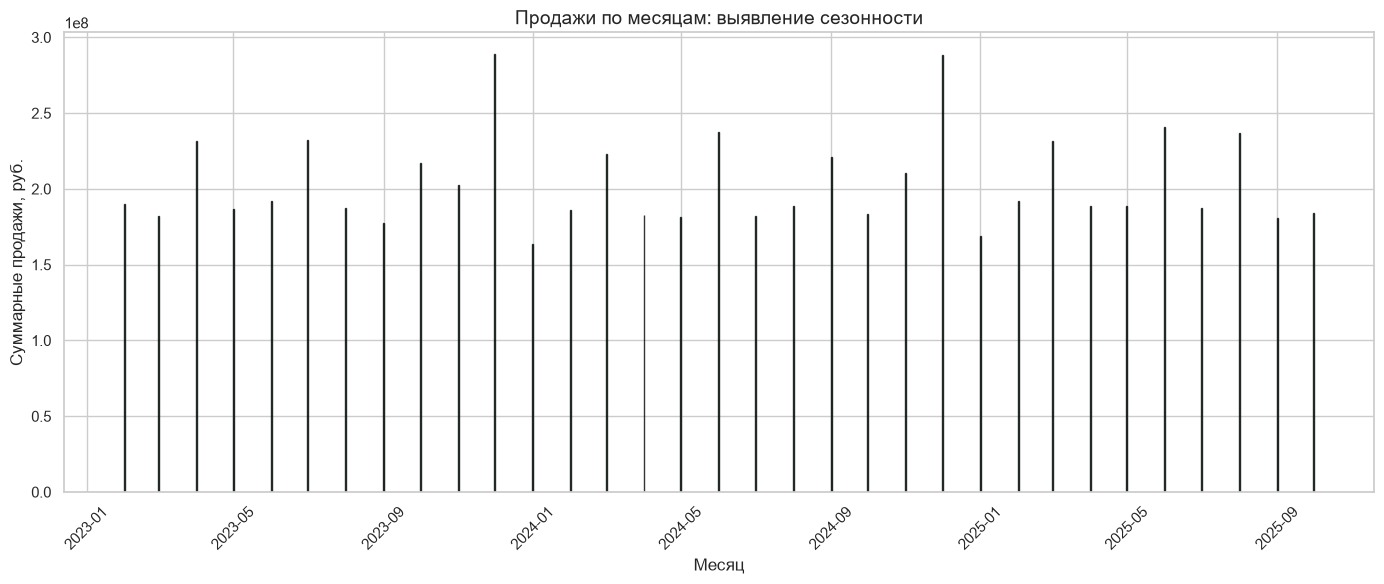

📊 Статистика по аномальным неделям:
  Всего недель: 143
  Аномальных недель: 12 (8.4%)
  Диапазон аномальных продаж: [39,599,853, 80,931,416] руб.


In [9]:
sns.set(style="whitegrid")
plt.rcParams["figure.figsize"] = (14, 6)

# --- Подготовка данных ---
df = df_sales.copy()
df['date'] = pd.to_datetime(df['date'])
df['YearMonth'] = df['date'].dt.to_period('M').astype(str)

# Агрегация по неделям
weekly_agg = (
    df.groupby('date')['weekly_sales']
      .sum()
      .reset_index()
      .rename(columns={'weekly_sales': 'Total_Weekly_Sales'})
)

# Агрегация по месяцам
monthly_agg = (
    df.groupby('YearMonth')['weekly_sales']
      .sum()
      .reset_index()
      .rename(columns={'weekly_sales': 'Total_Monthly_Sales'})
)
monthly_agg['YearMonth'] = pd.to_datetime(monthly_agg['YearMonth'])

# --- Выявление аномальных недель (IQR) ---
Q1 = weekly_agg['Total_Weekly_Sales'].quantile(0.25)
Q3 = weekly_agg['Total_Weekly_Sales'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

weekly_agg['Is_Anomaly'] = (weekly_agg['Total_Weekly_Sales'] < lower_bound) | \
                           (weekly_agg['Total_Weekly_Sales'] > upper_bound)

# Праздничные недели
holiday_weeks = df[df['is_holiday'] == True].groupby('date')['weekly_sales'].sum().reset_index()
holiday_weeks.rename(columns={'weekly_sales': 'Holiday_Sales'}, inplace=True)

# --- График 1: Динамика по неделям ---
fig, ax = plt.subplots()

normal_weeks = weekly_agg[~weekly_agg['Is_Anomaly']]
ax.plot(normal_weeks['date'], normal_weeks['Total_Weekly_Sales'],
        label='Обычные недели', color='steelblue', linewidth=1.2)

anomaly_weeks = weekly_agg[weekly_agg['Is_Anomaly']]
ax.scatter(anomaly_weeks['date'], anomaly_weeks['Total_Weekly_Sales'],
           color='red', s=40, label='Аномальные недели', zorder=3)

if not holiday_weeks.empty:
    ax.scatter(holiday_weeks['date'], holiday_weeks['Holiday_Sales'],
               color='orange', s=30, label='Праздничные недели', marker='^', zorder=4)

ax.set_title('Динамика продаж по неделям: сезонность, всплески и аномалии', fontsize=14)
ax.set_xlabel('Дата (начало недели)')
ax.set_ylabel('Суммарные продажи, руб.')
ax.legend(loc='upper left')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# --- График 2: Продажи по месяцам ---
fig, ax = plt.subplots()
ax.bar(monthly_agg['YearMonth'], monthly_agg['Total_Monthly_Sales'],
       color='seagreen', alpha=0.8, edgecolor='black')

ax.set_title('Продажи по месяцам: выявление сезонности', fontsize=14)
ax.set_xlabel('Месяц')
ax.set_ylabel('Суммарные продажи, руб.')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# --- Статистика по аномалиям ---
print("📊 Статистика по аномальным неделям:")
print(f"  Всего недель: {len(weekly_agg)}")
print(f"  Аномальных недель: {weekly_agg['Is_Anomaly'].sum()} ({weekly_agg['Is_Anomaly'].mean()*100:.1f}%)")
if weekly_agg['Is_Anomaly'].any():
    print(f"  Диапазон аномальных продаж: [{weekly_agg.loc[weekly_agg['Is_Anomaly'], 'Total_Weekly_Sales'].min():,.0f}, "
          f"{weekly_agg.loc[weekly_agg['Is_Anomaly'], 'Total_Weekly_Sales'].max():,.0f}] руб.")


Здесь можно заметить яные всплески продаж в конце года перед праздниками.

**Задача:** объедините три таблицы в одну для дальнейшего анализа.


In [10]:
df_sales['date'] = pd.to_datetime(df_sales['date'])
df_features['date'] = pd.to_datetime(df_features['date'])

df_merged = pd.merge(
    df_sales,
    df_stores,
    on='store',
    how='left',
    suffixes=('', '_store')
)

df = pd.merge(
    df_merged,
    df_features,
    on=['store', 'dept', 'date'],
    how='left',
    suffixes=('', '_feat')
)

print("Размер итогового датасета:", df.shape)
print("\nПервые 5 строк:")
display(df.head())
print("\nПропуски после объединения:")
print(df.isna().sum()[df.isna().sum() > 0])

Размер итогового датасета: (421570, 16)

Первые 5 строк:


,store,dept,date,weekly_sales,is_holiday,type,size,temperature,fuel_price,factor1,factor2,factor3,factor4,factor5,cpi,unemployment
0,1,1,2023-02-05,24924.50,False,A,151315,42.31,2.572,7028.8,NaN,NaN,NaN,NaN,211.096358,8.106
1,29,5,2023-02-05,15552.08,False,B,93638,24.36,2.788,7028.8,NaN,NaN,NaN,NaN,131.527903,10.064
2,29,6,2023-02-05,3200.22,False,B,93638,24.36,2.788,7028.8,NaN,NaN,NaN,NaN,131.527903,10.064
3,29,7,2023-02-05,10820.05,False,B,93638,24.36,2.788,7028.8,NaN,NaN,NaN,NaN,131.527903,10.064
4,29,8,2023-02-05,20055.64,False,B,93638,24.36,2.788,7028.8,NaN,NaN,NaN,NaN,131.527903,10.064



Пропуски после объединения:
factor2    310322
factor3    284479
factor4    286603
factor5    270138
dtype: int64


In [11]:
df.columns

Index(['store', 'dept', 'date', 'weekly_sales', 'is_holiday', 'type', 'size',
       'temperature', 'fuel_price', 'factor1', 'factor2', 'factor3', 'factor4',
       'factor5', 'cpi', 'unemployment'],
      dtype='object')

**Задача:** оценить корреляцию целевой переменной `Weekly_Sales` с другими признаками.


Пропуски до корреляционного анализа:
store                0
dept                 0
date                 0
weekly_sales         0
is_holiday           0
type                 0
size                 0
temperature          0
fuel_price           0
factor1              0
factor2         310322
factor3         284479
factor4         286603
factor5         270138
cpi                  0
unemployment         0
dtype: int64


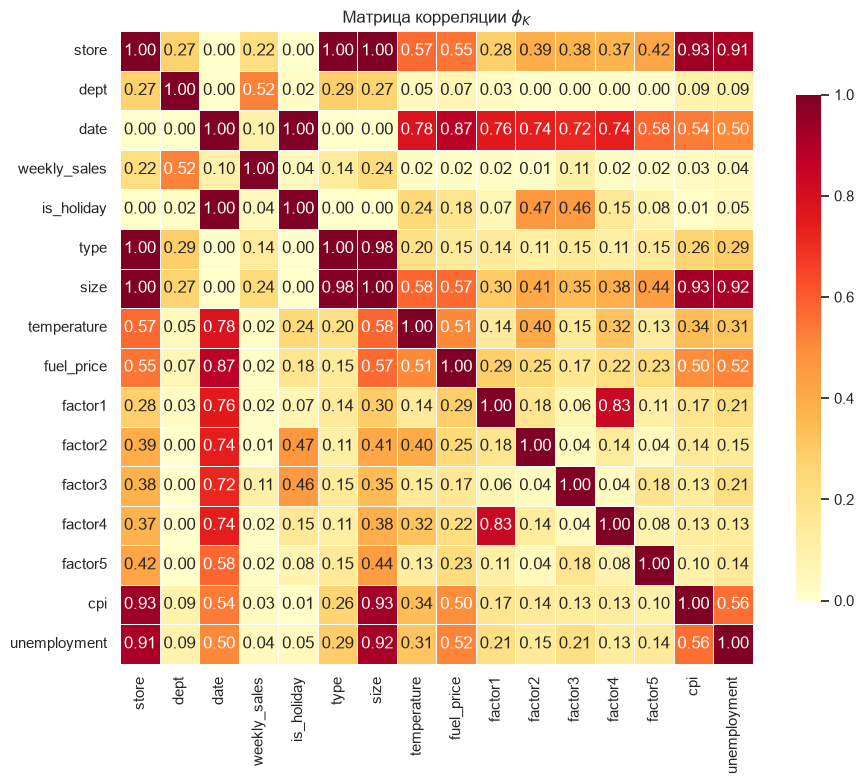

In [12]:
# Шаг 1: проверка пропусков и их заполнение (если нужно)
print("\nПропуски до корреляционного анализа:")
print(df.isna().sum())

# Заполним пропуски (например, нулями для MarkDown)
markdown_cols = [c for c in df.columns if c.startswith('MarkDown')]
for c in markdown_cols:
    df[c] = df[c].fillna(0)

# Расчёт матрицы phi_k
phik_corr = df.phik_matrix(interval_cols = ['weekly_sales', 'temperature', 'fuel_price', 'factor1', 'factor2', 'factor3', 'factor4',
       'factor5', 'cpi', 'unemployment'])


plt.figure(figsize=(10, 8))
sns.heatmap(phik_corr, annot=True, fmt='.2f', cmap='YlOrRd',
            square=True, linewidths=0.5, cbar_kws={'shrink': 0.8})
plt.title(r'Матрица корреляции $\phi_K$')
plt.tight_layout()
plt.show()

weekly_sales наиболее сильно коррелирует с:

- store (0.2223)
- dept (0.5231)
- type (0.1401)
- size (0.2369)

In [13]:
df.describe()

,store,dept,date,weekly_sales,size,temperature,fuel_price,factor1,factor2,factor3,factor4,factor5,cpi,unemployment
count,421570.000000,421570.000000,421570,421570.000000,421570.000000,421570.000000,421570.000000,421570.000000,111248.000000,137091.000000,134967.000000,151432.000000,421570.000000,421570.000000
mean,22.200546,44.260317,2024-06-17 08:30:31.963375360,15981.258123,136727.915739,60.090059,3.361027,10337.221240,3334.628621,1439.421384,3383.168256,4628.975079,171.201947,7.960289
min,1.000000,1.000000,2023-02-05 00:00:00,-4988.940000,34875.000000,-2.060000,2.472000,7028.800000,-265.760000,-29.100000,0.220000,135.160000,126.064000,3.879000
25%,11.000000,18.000000,2023-10-08 00:00:00,2079.650000,93638.000000,46.680000,2.933000,7028.800000,41.600000,5.080000,504.220000,1878.440000,132.022667,6.891000
50%,22.000000,37.000000,2024-06-16 00:00:00,7612.030000,140167.000000,62.090000,3.452000,7028.800000,192.000000,24.600000,1481.310000,3359.450000,182.318780,7.866000
75%,33.000000,74.000000,2025-02-23 00:00:00,20205.852500,202505.000000,74.280000,3.738000,9431.920624,1926.940000,103.990000,3595.040000,5563.800000,212.416993,8.572000
max,45.000000,99.000000,2025-10-26 00:00:00,693099.360000,219622.000000,100.140000,4.468000,103184.980000,104519.540000,141630.610000,67474.850000,108519.280000,227.232807,14.313000
std,12.785297,30.492054,NaN,22711.183519,60980.583328,18.447931,0.458515,9502.153632,9475.357325,9623.078290,6292.384031,5962.887455,39.159276,1.863296


In [14]:
# --- Анализ отрицательных продаж ---
neg_count = (df['weekly_sales'] < 0).sum()
total_count = len(df)
neg_pct = neg_count / total_count * 100

print(f"Всего строк: {total_count:,}")
print(f"Отрицательных продаж: {neg_count} ({neg_pct:.2f}%)")
print(f"Диапазон отрицательных значений: [{df.loc[df['weekly_sales'] < 0, 'weekly_sales'].min():.0f}, "
      f"{df.loc[df['weekly_sales'] < 0, 'weekly_sales'].max():.0f}]")

# --- Обработка: обнуляем ---
df['weekly_sales'] = df['weekly_sales'].clip(lower=0)

# Проверка после
print(f"\nПосле обработки:")
print(f"Минимальное значение weekly_sales: {df['weekly_sales'].min():.0f}")
print(f"Отрицательных значений осталось: {(df['weekly_sales'] < 0).sum()}")

Всего строк: 421,570
Отрицательных продаж: 1285 (0.30%)
Диапазон отрицательных значений: [-4989, -0]

После обработки:
Минимальное значение weekly_sales: 0
Отрицательных значений осталось: 0


Отрицательные продажи = возвраты. Для прогноза закупок нужен физический спрос, а не чистая выручка. Отрицательный прогноз невозможно использовать для заказа поставщику.

Порог (99.99-й квантиль): 283,660 руб.
Медиана продаж: 7,612 руб.
Максимум: 693,099 руб.

Количество аномальных записей: 43
Доля от общего числа: 0.0102%

--- Распределение аномальных продаж по месяцам ---
       count     mean_sales  median_sales
month                                    
11        31  394502.882581     359995.60
12        11  329678.243636     313933.22
2          1  293966.050000     293966.05


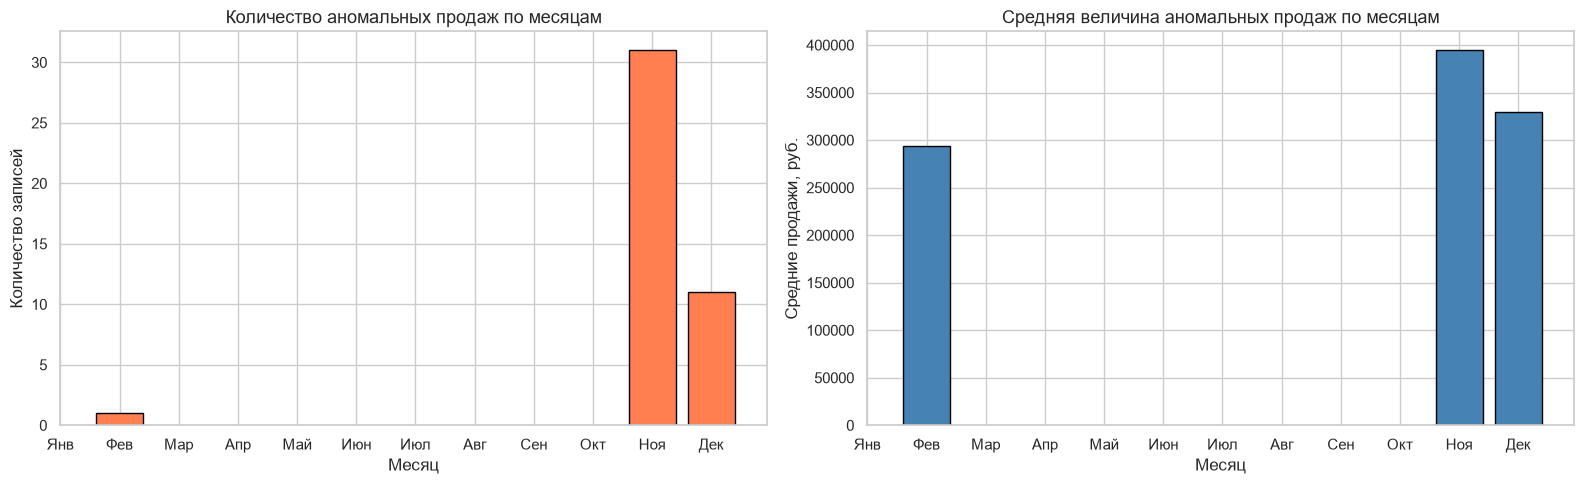


--- Связь аномальных продаж с праздниками ---
                    count     mean_sales  median_sales
Обычные недели         12  326702.227500     308469.83
Праздничные недели     31  394502.882581     359995.60

Доля праздничных недель среди аномалий: 72.09%
Доля праздничных недель среди всех данных: 7.04%
Отношение (во сколько раз чаще): 10.2x


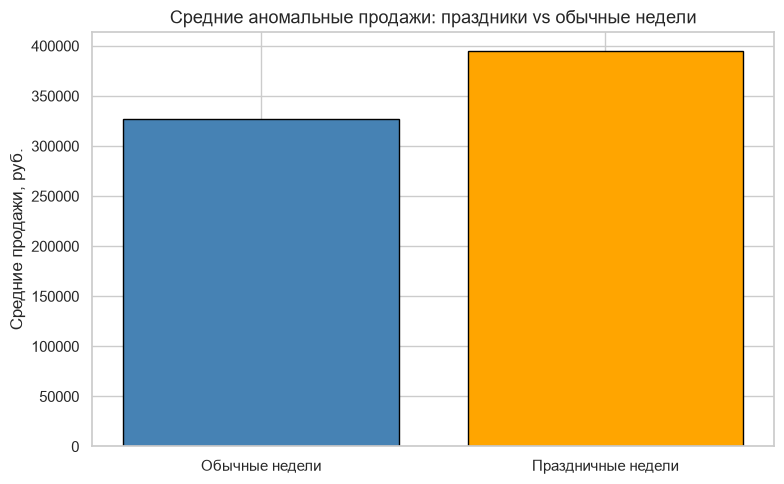


--- Топ-10 дарксторов по количеству аномальных записей ---
            count     mean_sales  max_sales
store type                                 
10    B         6  462211.416667  693099.36
14    A         5  363008.986000  474330.10
4     A         5  335488.238000  385051.04
20    A         3  372445.236667  422306.25
19    A         2  318181.720000  339846.03
28    A         2  353560.050000  355356.39
6     A         2  334722.625000  342578.65
12    B         2  360068.130000  360140.66
39    A         2  345627.300000  351553.98
35    B         2  638866.555000  649770.18

--- Топ-10 отделов по количеству аномальных записей ---
      count     mean_sales  max_sales
dept                                 
72       36  384623.960833  693099.36
7         6  334931.241667  406988.63
92        1  293966.050000  293966.05

--- Распределение аномалий по типам дарксторов ---
      count     mean_sales  median_sales
type                                    
A        26  345054.017692     

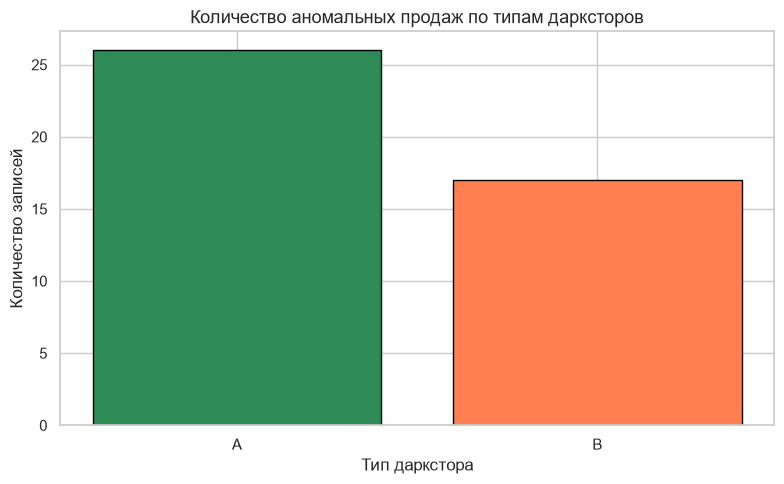


--- Топ-15 записей с самыми высокими продажами ---
 store  dept       date  weekly_sales  is_holiday type   size
    10    72 2023-11-26     693099.36        True    B 126512
    35    72 2024-11-24     649770.18        True    B 103681
    10    72 2024-11-24     630999.19        True    B 126512
    35    72 2023-11-26     627962.93        True    B 103681
    14    72 2023-11-26     474330.10        True    A 200898
    20    72 2023-11-26     422306.25        True    A 203742
    27    72 2023-11-26     420586.57        True    A 204184
    10     7 2023-12-24     406988.63       False    B 126512
    10    72 2023-12-24     404245.03       False    B 126512
    22    72 2023-11-26     393705.20        True    B 119557
    20    72 2024-11-24     392023.02        True    A 203742
     4    72 2024-11-24     385051.04        True    A 205863
     4    72 2023-11-26     381072.11        True    A 205863
    14    72 2024-11-24     375948.31        True    A 200898
    23    72 2023-

In [15]:

sns.set(style="whitegrid")
plt.rcParams["figure.figsize"] = (14, 6)

# --- Шаг 1: определение порога аномально высоких продаж ---
threshold = df['weekly_sales'].quantile(0.9999)
print(f"Порог (99.99-й квантиль): {threshold:,.0f} руб.")
print(f"Медиана продаж: {df['weekly_sales'].median():,.0f} руб.")
print(f"Максимум: {df['weekly_sales'].max():,.0f} руб.")

# Выделяем аномальные записи
df_high = df[df['weekly_sales'] >= threshold].copy()
print(f"\nКоличество аномальных записей: {len(df_high)}")
print(f"Доля от общего числа: {len(df_high) / len(df) * 100:.4f}%")

# --- Шаг 2: в какое время года происходят пики ---
df_high['month'] = df_high['date'].dt.month
df_high['year'] = df_high['date'].dt.year

print("\n--- Распределение аномальных продаж по месяцам ---")
by_month = df_high.groupby('month').agg(
    count=('weekly_sales', 'size'),
    mean_sales=('weekly_sales', 'mean'),
    median_sales=('weekly_sales', 'median')
).sort_values('count', ascending=False)
print(by_month)

# График: количество аномалий по месяцам
fig, ax = plt.subplots(1, 2, figsize=(16, 5))

month_counts = df_high['month'].value_counts().sort_index()
ax[0].bar(month_counts.index, month_counts.values, color='coral', edgecolor='black')
ax[0].set_title('Количество аномальных продаж по месяцам', fontsize=13)
ax[0].set_xlabel('Месяц')
ax[0].set_ylabel('Количество записей')
ax[0].set_xticks(range(1, 13))
ax[0].set_xticklabels(['Янв', 'Фев', 'Мар', 'Апр', 'Май', 'Июн',
                       'Июл', 'Авг', 'Сен', 'Окт', 'Ноя', 'Дек'])

# График: средняя величина аномальных продаж по месяцам
month_means = df_high.groupby('month')['weekly_sales'].mean().sort_index()
ax[1].bar(month_means.index, month_means.values, color='steelblue', edgecolor='black')
ax[1].set_title('Средняя величина аномальных продаж по месяцам', fontsize=13)
ax[1].set_xlabel('Месяц')
ax[1].set_ylabel('Средние продажи, руб.')
ax[1].set_xticks(range(1, 13))
ax[1].set_xticklabels(['Янв', 'Фев', 'Мар', 'Апр', 'Май', 'Июн',
                       'Июл', 'Авг', 'Сен', 'Окт', 'Ноя', 'Дек'])
plt.tight_layout()
plt.show()

# --- Шаг 3: связь с праздниками ---
print("\n--- Связь аномальных продаж с праздниками ---")
holiday_stats = df_high.groupby('is_holiday').agg(
    count=('weekly_sales', 'size'),
    mean_sales=('weekly_sales', 'mean'),
    median_sales=('weekly_sales', 'median')
)
holiday_stats.index = ['Обычные недели', 'Праздничные недели']
print(holiday_stats)

# Сравнение: доля праздничных недель среди аномалий vs среди всех данных
holiday_rate_anomalies = df_high['is_holiday'].mean()
holiday_rate_all = df['is_holiday'].mean()
print(f"\nДоля праздничных недель среди аномалий: {holiday_rate_anomalies:.2%}")
print(f"Доля праздничных недель среди всех данных: {holiday_rate_all:.2%}")
print(f"Отношение (во сколько раз чаще): {holiday_rate_anomalies / holiday_rate_all:.1f}x" if holiday_rate_all > 0 else "")

# График: продажи в праздничные vs обычные недели (среди аномалий)
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(['Обычные недели', 'Праздничные недели'],
       holiday_stats['mean_sales'].values,
       color=['steelblue', 'orange'], edgecolor='black')
ax.set_title('Средние аномальные продажи: праздники vs обычные недели', fontsize=13)
ax.set_ylabel('Средние продажи, руб.')
plt.tight_layout()
plt.show()

# --- Шаг 4: типы дарксторов и отделы с пиковыми продажами ---
print("\n--- Топ-10 дарксторов по количеству аномальных записей ---")
top_stores = df_high.groupby(['store', 'type']).agg(
    count=('weekly_sales', 'size'),
    mean_sales=('weekly_sales', 'mean'),
    max_sales=('weekly_sales', 'max')
).sort_values('count', ascending=False).head(10)
print(top_stores)

print("\n--- Топ-10 отделов по количеству аномальных записей ---")
top_depts = df_high.groupby('dept').agg(
    count=('weekly_sales', 'size'),
    mean_sales=('weekly_sales', 'mean'),
    max_sales=('weekly_sales', 'max')
).sort_values('count', ascending=False).head(10)
print(top_depts)

print("\n--- Распределение аномалий по типам дарксторов ---")
by_type = df_high.groupby('type').agg(
    count=('weekly_sales', 'size'),
    mean_sales=('weekly_sales', 'mean'),
    median_sales=('weekly_sales', 'median')
).sort_values('count', ascending=False)
print(by_type)

# График: аномальные продажи по типам дарксторов
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(by_type.index, by_type['count'].values, color=['seagreen', 'coral', 'slateblue'], edgecolor='black')
ax.set_title('Количество аномальных продаж по типам дарксторов', fontsize=13)
ax.set_xlabel('Тип даркстора')
ax.set_ylabel('Количество записей')
plt.tight_layout()
plt.show()

# --- Шаг 5: детальный взгляд на конкретные аномальные недели ---
print("\n--- Топ-15 записей с самыми высокими продажами ---")
top_records = df_high.nlargest(15, 'weekly_sales')[['store', 'dept', 'date', 'weekly_sales', 'is_holiday', 'type', 'size']]
print(top_records.to_string(index=False))

# --- Итоговый отчёт ---
print("\n" + "="*60)
print("ИТОГОВЫЙ ОТЧЁТ ПО АНОМАЛЬНО ВЫСОКИМ ПРОДАЖАМ")
print("="*60)
print(f"Порог аномалии (99.99%): {threshold:,.0f} руб.")
print(f"Всего аномальных записей: {len(df_high)}")
print(f"Пик: {df_high['weekly_sales'].max():,.0f} руб.")
print(f"Топ-месяц по количеству аномалий: {by_month.index[0]} ({by_month.iloc[0]['count']} записей)")
print(f"Топ-тип даркстора: {by_type.index[0]} ({by_type.iloc[0]['count']} записей)")
print(f"Топ-отдел: {top_depts.index[0]} ({top_depts.iloc[0]['count']} записей)")
print(f"Доля праздничных недель среди аномалий: {holiday_rate_anomalies:.1%}")
print(f"Доля праздничных недель в среднем: {holiday_rate_all:.1%}")


72% аномалий приходятся на ноябрь, 26% — на декабрь. Это два ярких сезонных пика в год.

### Шаг 2. Предобработка признаков и feature engineering

**Задача:** реализуем функцию `create_temporal_features` для извлечения временных признаков из столбца `Date`.

Эти признаки помогут модели уловить сезонные паттерны.

In [16]:
def create_temporal_features(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df['date'] = pd.to_datetime(df['date'])
    
    df['month'] = df['date'].dt.month
    df['quarter'] = df['date'].dt.quarter
    df['year'] = df['date'].dt.year
    
    return df

df = create_temporal_features(df)


In [17]:
assert 'month' in df.columns, 'Месяц не создан!'
assert 'quarter' in df.columns, 'Квартал не создан!'
assert 'year' in df.columns, 'Год не создан!'

**Задача:** cоздаём агрегированные признаки в функции `create_avg_sales_feature` — средние продажи по комбинации «даркстор и отдел».

In [18]:
def create_avg_sales_feature(df: pd.DataFrame) -> pd.DataFrame:
    
    df = df.copy()
    
    # Сохраняем исходный порядок строк
    df['_orig_idx'] = range(len(df))
    
    # Сортируем по группе и дате — нужно для корректного expanding
    df = df.sort_values(['store', 'dept', 'date']).reset_index(drop=True)
    
    # Для каждой группы (store, dept) считаем expanding mean,
    # затем сдвигаем на 1 — чтобы текущая строка не попала в расчёт
    df['avg_sales_before'] = df.groupby(['store', 'dept'])['weekly_sales'].transform(
        lambda x: x.expanding().mean().shift(1)
    )
    
    global_mean = df['weekly_sales'].mean()
    df['avg_sales_before'] = df['avg_sales_before'].fillna(global_mean)
    
    # Возвращаем исходный порядок
    df = df.sort_values('_orig_idx').drop(columns='_orig_idx')
    df = df.reset_index(drop=True)
    
    return df

df = create_avg_sales_feature(df)


In [19]:
assert 'avg_sales_before' in df.columns, 'Признак средних продаж не создан!'

**Задача:** создайте лаговые признаки в функции `create_lag_features` — продажи 1, 2 и 4 недели назад.

Лаговые признаки позволяют модели учитывать историю продаж:
- `sales_1week_ago` — продажи неделю назад.
- `sales_2week_ago` — продажи 2 недели назад.
- `sales_4week_ago` — продажи 4 недели назад.

Это одни из самых важных признаков для прогнозирования временных рядов!

In [20]:
def create_lag_features(df):
    df = df.copy()
    
    # Сохраняем исходный порядок
    df['_orig_idx'] = range(len(df))
    
    # Сортируем по группе и дате
    df = df.sort_values(['store', 'dept', 'date']).reset_index(drop=True)
    
    # Лаги: shift(1), shift(2), shift(4) внутри каждой группы
    df['sales_1week_ago'] = df.groupby(['store', 'dept'])['weekly_sales'].shift(1)
    df['sales_2week_ago'] = df.groupby(['store', 'dept'])['weekly_sales'].shift(2)
    df['sales_4week_ago'] = df.groupby(['store', 'dept'])['weekly_sales'].shift(4)
    
    # Возвращаем исходный порядок
    df = df.sort_values('_orig_idx').drop(columns='_orig_idx')
    df = df.reset_index(drop=True)
    
    return df

df = create_lag_features(df)

df = create_lag_features(df)

In [21]:
assert 'sales_1week_ago' in df.columns, 'Признак sales_1week_ago не создан!'
assert 'sales_2week_ago' in df.columns, 'Признак sales_2week_ago не создан!'
assert 'sales_4week_ago' in df.columns, 'Признак sales_4week_ago не создан!'

**Задача:** cоздайте признаки скользящего среднего продаж за последние 2 и 4 недели в функции `create_rolling_features`.

Скользящее среднее сглаживает колебания и показывает общий тренд:
- `mean_sales_2week` — среднее продаж за последние 2 недели.
- `mean_sales_4week` — среднее продаж за последние 4 недели.

Эти признаки помогают уловить краткосрочные и среднесрочные тренды.

In [22]:
def create_rolling_features(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df['_orig_idx'] = range(len(df))
    df = df.sort_values(['store', 'dept', 'date']).reset_index(drop=True)

    df['mean_sales_2week'] = df.groupby(['store', 'dept'])['weekly_sales'].transform(
        lambda x: x.shift(1).rolling(window=2, min_periods=1).mean()
    )
    df['mean_sales_4week'] = df.groupby(['store', 'dept'])['weekly_sales'].transform(
        lambda x: x.shift(1).rolling(window=4, min_periods=1).mean()
    )

    df = df.sort_values('_orig_idx').drop(columns='_orig_idx')
    df = df.reset_index(drop=True)
    return df

df = create_rolling_features(df)


In [23]:
assert 'mean_sales_2week' in df.columns, 'Признак mean_sales_2week не создан!'
assert 'mean_sales_4week' in df.columns, 'Признак mean_sales_4week не создан!'

**Задача:** удалите строки с пропусками.

После создания лаговых и агрегированных признаков неизбежно появятся пропуски (особенно для первых недель, где нет истории). Удалите такие строки с помощью `dropna()`.

In [24]:
# Сначала заполняем пропуски в factor-колонках (промо-данные)
factor_cols = ['factor2', 'factor3', 'factor4', 'factor5']
for col in factor_cols:
    df[col] = df[col].fillna(0)

# Теперь dropna удалит только строки с пропусками в лагах/rolling
# (это первые недели для каждой группы — ожидаемо и безопасно)
print(f"Строк до удаления: {len(df)}")
df = df.dropna().reset_index(drop=True)
print(f"Строк после удаления: {len(df)}")

Строк до удаления: 421570
Строк после удаления: 408436


### Шаг 3. Мониторинг стабильности признаков

**Задача:** разделите данные на обучающую и валидационную выборки **по времени**.

Разделение:
- **Обучение**: февраль 2023 — август 2025.
- **Валидация**: сентябрь 2025 — октябрь 2025.

Такое разделение имитирует реальное применение модели: обучаем на прошлых данных, проверяем на будущих.

In [25]:
# Разделение по дате
train = df[df['date'] < '2025-09-01'].copy()
val = df[df['date'] >= '2025-09-01'].copy()

print(f"Обучающая выборка: {len(train):,} строк")
print(f"  Период: {train['date'].min().date()} — {train['date'].max().date()}")
print(f"Валидационная выборка: {len(val):,} строк")
print(f"  Период: {val['date'].min().date()} — {val['date'].max().date()}")
print(f"Доля валидации: {len(val) / (len(train) + len(val)) * 100:.1f}%")

assert train['date'].max() < val['date'].min(), "Даты пересекаются!"
print("\nПересечений по датам нет ✓")

Обучающая выборка: 384,726 строк
  Период: 2023-03-05 — 2025-08-31
Валидационная выборка: 23,710 строк
  Период: 2025-09-07 — 2025-10-26
Доля валидации: 5.8%

Пересечений по датам нет ✓


**Задача:** рассчитайте PSI для всех признаков.

PSI измеряет стабильность распределения признака между обучающей и валидационной выборками:
- **PSI < 0.1** — признак стабилен, можно использовать.
- **0.1 ≤ PSI < 0.2** — умеренный дрейф, требуется внимание.
- **PSI ≥ 0.2** — значительный дрейф, признак нестабилен.

In [26]:
def calculate_psi(train: pd.DataFrame, val: pd.DataFrame, feature: str, bins: int = 10) -> float:
    train_vals = train[feature].dropna()
    val_vals = val[feature].dropna()
    
    if len(train_vals) == 0 or len(val_vals) == 0:
        return np.nan
    
    # Если признак категориальный или целочисленный с малым числом уникальных значений
    n_unique = train_vals.nunique()
    if n_unique <= 10:
        # Считаем по категориям
        categories = sorted(set(train_vals.unique()) | set(val_vals.unique()))
        train_dist = train_vals.value_counts(normalize=True).reindex(categories, fill_value=1e-6)
        val_dist = val_vals.value_counts(normalize=True).reindex(categories, fill_value=1e-6)
    else:
        # Численный — квантильные бины по train
        quantiles = np.linspace(0, 1, bins + 1)
        boundaries = np.quantile(train_vals, quantiles)
        boundaries = np.unique(boundaries)
        
        if len(boundaries) < 3:
            # Слишком мало уникальных значений для биннинга
            return 0.0
        
        train_dist = np.histogram(train_vals, bins=boundaries)[0] / len(train_vals)
        val_dist = np.histogram(val_vals, bins=boundaries)[0] / len(val_vals)
        
        # Защита от нулей
        train_dist = np.where(train_dist == 0, 1e-6, train_dist)
        val_dist = np.where(val_dist == 0, 1e-6, val_dist)
    
    # PSI = sum((val% - train%) * ln(val% / train%))
    psi = np.sum((val_dist - train_dist) * np.log(val_dist / train_dist))
    
    return float(psi)


# --- Расчёт PSI для всех признаков ---
# Исключаем целевую переменную и технические колонки
exclude_cols = ['weekly_sales', 'date']
features = [col for col in train.columns if col not in exclude_cols]

psi_results = []
for feature in features:
    psi_value = calculate_psi(train, val, feature)
    if psi_value < 0.1:
        status = "Стабилен"
    elif psi_value < 0.2:
        status = "Умеренный дрейф"
    else:
        status = "Значительный дрейф"
    
    psi_results.append({
        'feature': feature,
        'psi': psi_value,
        'status': status
    })

psi_df = pd.DataFrame(psi_results).sort_values('psi', ascending=False)
psi_df = psi_df.reset_index(drop=True)

# --- Вывод ---
print("=" * 65)
print(f"{'Признак':<30} {'PSI':>10} {'Статус'}")
print("=" * 65)
for _, row in psi_df.iterrows():
    print(f"{row['feature']:<30} {row['psi']:>10.4f}   {row['status']}")
print("=" * 65)

# Сводка
stable = (psi_df['psi'] < 0.1).sum()
moderate = ((psi_df['psi'] >= 0.1) & (psi_df['psi'] < 0.2)).sum()
unstable = (psi_df['psi'] >= 0.2).sum()

print(f"\nСтабильных (PSI < 0.1):        {stable}")
print(f"Умеренный дрейф (0.1–0.2):     {moderate}")
print(f"Значительный дрейф (PSI ≥ 0.2): {unstable}")

Признак                               PSI Статус
year                              10.3217   Значительный дрейф
month                              9.9985   Значительный дрейф
quarter                            6.9819   Значительный дрейф
fuel_price                         6.5047   Значительный дрейф
cpi                                4.0845   Значительный дрейф
factor1                            1.9054   Значительный дрейф
factor5                            1.5977   Значительный дрейф
temperature                        1.3990   Значительный дрейф
factor2                            1.2216   Значительный дрейф
factor4                            0.6695   Значительный дрейф
factor3                            0.6248   Значительный дрейф
unemployment                       0.4061   Значительный дрейф
is_holiday                         0.0495   Стабилен
sales_4week_ago                    0.0024   Стабилен
mean_sales_4week                   0.0019   Стабилен
mean_sales_2week                   0

**Задача:** интерпретируйте результаты PSI.

Проанализируйте полученные значения PSI:
- Какие признаки стабильны?
- Для каких признаков наблюдается дрейф?

Визуализируйте распределения признаков с высоким PSI на обучении и валидации для лучшего понимания.

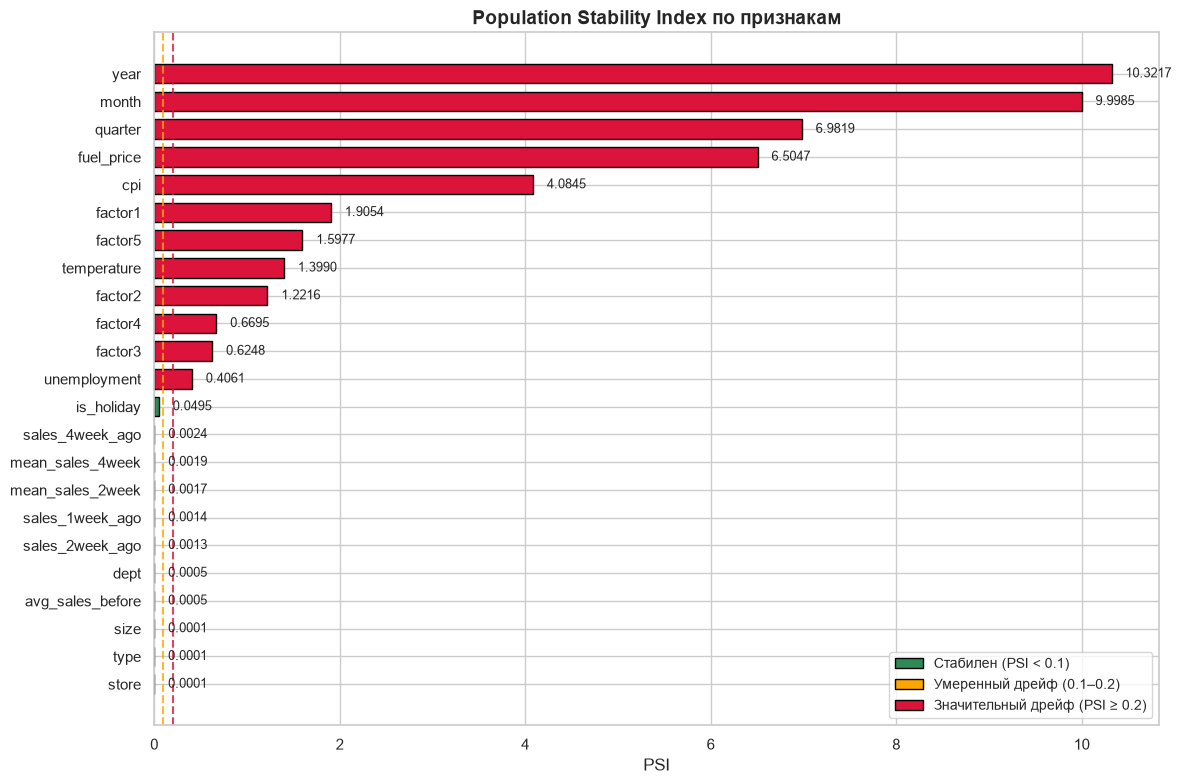

In [27]:
fig, ax = plt.subplots(figsize=(12, 8))

colors = []
for psi in psi_df['psi']:
    if psi < 0.1:
        colors.append('seagreen')
    elif psi < 0.2:
        colors.append('orange')
    else:
        colors.append('crimson')

bars = ax.barh(psi_df['feature'], psi_df['psi'], color=colors, edgecolor='black', height=0.7)

# Пороговые линии
ax.axvline(x=0.1, color='orange', linestyle='--', linewidth=1.5, alpha=0.8, label='PSI = 0.1 (умеренный дрейф)')
ax.axvline(x=0.2, color='crimson', linestyle='--', linewidth=1.5, alpha=0.8, label='PSI = 0.2 (значительный дрейф)')

# Подписи значений на столбцах
for bar, psi_val in zip(bars, psi_df['psi']):
    x = bar.get_width()
    ax.text(x + 0.15, bar.get_y() + bar.get_height() / 2,
            f'{psi_val:.4f}', va='center', fontsize=9)

ax.set_xlabel('PSI', fontsize=12)
ax.set_title('Population Stability Index по признакам', fontsize=14, fontweight='bold')
ax.invert_yaxis()
ax.legend(loc='lower right', fontsize=10)

# Легенда по цветам
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='seagreen', edgecolor='black', label='Стабилен (PSI < 0.1)'),
    Patch(facecolor='orange', edgecolor='black', label='Умеренный дрейф (0.1–0.2)'),
    Patch(facecolor='crimson', edgecolor='black', label='Значительный дрейф (PSI ≥ 0.2)'),
]
ax.legend(handles=legend_elements, loc='lower right', fontsize=10)

plt.tight_layout()
plt.show()

**Задача:** удалите признаки с PSI ≥ 0.2.

Признаки с высоким PSI нестабильны и могут ухудшить качество модели в будущем. Удалите их из обучающей и валидационной выборок.

In [28]:
# Признаки с PSI >= 0.2 — удаляем
unstable_features = psi_df[psi_df['psi'] >= 0.2]['feature'].tolist()
print(f"Удаляемые признаки (PSI >= 0.2): {len(unstable_features)}")
for f in unstable_features:
    print(f"  {f}: {psi_df[psi_df['feature'] == f]['psi'].values[0]:.4f}")

# Удаляем из train и val
train = train.drop(columns=unstable_features)
val = val.drop(columns=unstable_features)

# Что осталось
stable_features = psi_df[psi_df['psi'] < 0.2]['feature'].tolist()
print(f"\nОставшиеся признаки: {len(stable_features)}")
for f in stable_features:
    print(f"  {f}: {psi_df[psi_df['feature'] == f]['psi'].values[0]:.4f}")

print(f"\nTrain: {train.shape}, Val: {val.shape}")


Удаляемые признаки (PSI >= 0.2): 12
  year: 10.3217
  month: 9.9985
  quarter: 6.9819
  fuel_price: 6.5047
  cpi: 4.0845
  factor1: 1.9054
  factor5: 1.5977
  temperature: 1.3990
  factor2: 1.2216
  factor4: 0.6695
  factor3: 0.6248
  unemployment: 0.4061

Оставшиеся признаки: 11
  is_holiday: 0.0495
  sales_4week_ago: 0.0024
  mean_sales_4week: 0.0019
  mean_sales_2week: 0.0017
  sales_1week_ago: 0.0014
  sales_2week_ago: 0.0013
  dept: 0.0005
  avg_sales_before: 0.0005
  size: 0.0001
  type: 0.0001
  store: 0.0001

Train: (384726, 13), Val: (23710, 13)


### Шаг 4. Обучение модели CatBoost

**Задача:** обучите модель CatBoost.

Используйте **обучающую** выборку.

In [29]:
import optuna
from catboost import CatBoostRegressor, Pool
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# --- Подбор гиперпараметров ---
exclude = ['weekly_sales', 'date']
features = [col for col in train.columns if col not in exclude]
cat_features = ['store', 'dept', 'type']

train_pool = Pool(train[features], train['weekly_sales'], cat_features=cat_features)
val_pool = Pool(val[features], val['weekly_sales'], cat_features=cat_features)

def objective(trial):
    params = {
        'iterations': trial.suggest_int('iterations', 200, 1500),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'depth': trial.suggest_int('depth', 4, 10),
        'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1, 10),
        'random_strength': trial.suggest_float('random_strength', 0, 10),
        'bagging_temperature': trial.suggest_float('bagging_temperature', 0, 1),
        'loss_function': 'RMSE',
        'eval_metric': 'RMSE',
        'random_seed': 42,
        'verbose': False,
        'early_stopping_rounds': 50,
    }
    
    model = CatBoostRegressor(**params)
    model.fit(train_pool, eval_set=val_pool, use_best_model=True)
    preds = model.predict(val_pool)
    return np.sqrt(mean_squared_error(val['weekly_sales'], preds))

study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=30, show_progress_bar=True)

print("\n" + "=" * 50)
print("    Лучшие гиперпараметры")
print("=" * 50)
for key, value in study.best_params.items():
    print(f"  {key}: {value}")
print(f"\n  Лучший RMSE: {study.best_value:.2f}")
print("=" * 50)

# --- Обучение финальной модели на лучших параметрах ---
best_params = study.best_params
best_params.update({
    'loss_function': 'RMSE',
    'eval_metric': 'RMSE',
    'random_seed': 42,
    'verbose': 100,
    'early_stopping_rounds': 50,
})

cb = CatBoostRegressor(**best_params)
cb.fit(train_pool, eval_set=val_pool, use_best_model=True)

# --- Оценка ---
preds = cb.predict(val_pool)
mae = mean_absolute_error(val['weekly_sales'], preds)
rmse = np.sqrt(mean_squared_error(val['weekly_sales'], preds))
r2 = r2_score(val['weekly_sales'], preds)

print("\n" + "=" * 50)
print("  Финальная модель — оценка на валидации")
print("=" * 50)
print(f"  MAE  = {mae:>12,.2f}")
print(f"  RMSE = {rmse:>12,.2f}")
print(f"  R²   = {r2:>12,.4f}")
print("=" * 50)
print(f"  Новый RMSE:    {rmse:,.2f}")



[I 2026-10-06 21:47:02,539] A new study created in memory with name: no-name-b9f2d03b-a01c-4561-b9f3-914c46e36986


  0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-10-06 21:47:27,007] Trial 0 finished with value: 3210.9637831154396 and parameters: {'iterations': 1429, 'learning_rate': 0.022339877451937204, 'depth': 8, 'l2_leaf_reg': 2.7004611715256535, 'random_strength': 9.15627484565292, 'bagging_temperature': 0.30210713525861865}. Best is trial 0 with value: 3210.9637831154396.
[I 2026-10-06 21:47:36,715] Trial 1 finished with value: 3175.1437798461975 and parameters: {'iterations': 1070, 'learning_rate': 0.07411458626493278, 'depth': 7, 'l2_leaf_reg': 1.6961579026876255, 'random_strength': 2.3052915719244336, 'bagging_temperature': 0.21642503350321096}. Best is trial 1 with value: 3175.1437798461975.
[I 2026-10-06 21:47:48,432] Trial 2 finished with value: 3259.0761002223844 and parameters: {'iterations': 1068, 'learning_rate': 0.08199963514372159, 'depth': 10, 'l2_leaf_reg': 2.170157973975517, 'random_strength': 8.474851952773136, 'bagging_temperature': 0.6872396315981003}. Best is trial 1 with value: 3175.1437798461975.
[I 2026-10-06

**Задача:** оцените качество модели на валидационной выборке.

Используйте метрики:
- **MAE**.
- **RMSE**.
- **R²**.

**Задача:** проанализируйте важность признаков.

Она показывает, какие признаки наиболее важны для модели:
- Проверьте, нет ли в топе признаков, которые могут приводить к утечке данных.
- Посмотрите, какие признаки действительно влияют на продажи.


    Важность признаков
  sales_1week_ago            32.21  ████████████████
  mean_sales_2week           23.33  ███████████
  mean_sales_4week           15.57  ███████
  sales_4week_ago            10.43  █████
  avg_sales_before            9.42  ████
  sales_2week_ago             7.37  ███
  is_holiday                  1.29  
  dept                        0.33  
  size                        0.03  
  store                       0.02  
  type                        0.01  


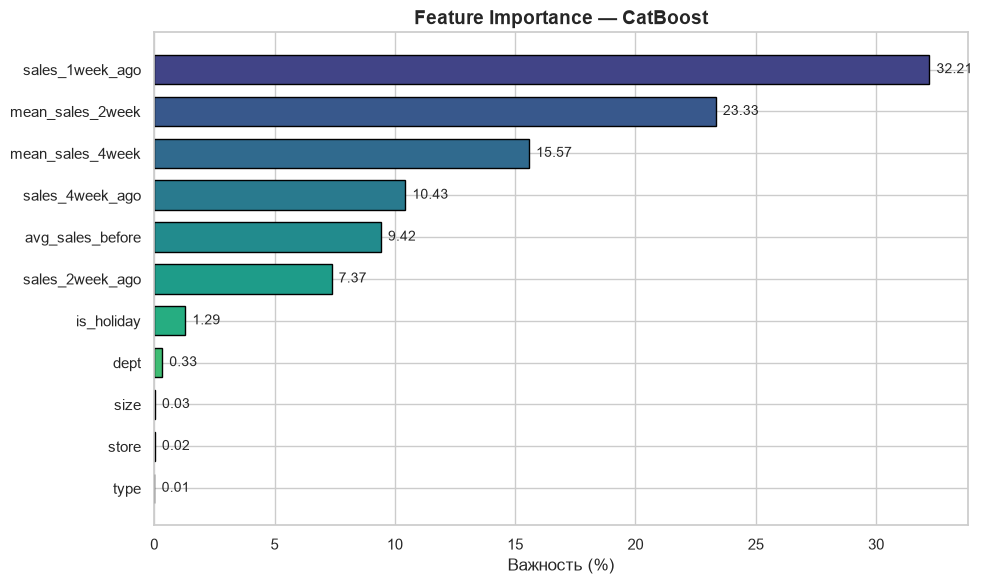

In [30]:
# --- Важность признаков ---
importance = cb.get_feature_importance()
importance_df = pd.DataFrame({
    'feature': features,
    'importance': importance
}).sort_values('importance', ascending=False).reset_index(drop=True)

print("=" * 45)
print("    Важность признаков")
print("=" * 45)
for _, row in importance_df.iterrows():
    bar = '█' * int(row['importance'] / 2)
    print(f"  {row['feature']:<25} {row['importance']:>6.2f}  {bar}")
print("=" * 45)

# --- Визуализация ---
fig, ax = plt.subplots(figsize=(10, 6))
colors = plt.cm.viridis(np.linspace(0.2, 0.9, len(importance_df)))
bars = ax.barh(importance_df['feature'], importance_df['importance'], 
               color=colors, edgecolor='black', height=0.7)

for bar, val in zip(bars, importance_df['importance']):
    ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height() / 2,
            f'{val:.2f}', va='center', fontsize=10)

ax.set_xlabel('Важность (%)', fontsize=12)
ax.set_title('Feature Importance — CatBoost', fontsize=14, fontweight='bold')
ax.invert_yaxis()
plt.tight_layout()
plt.show()